# Exploratory Data Analysis

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/hour.csv")

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [3]:
# Check column types and missing values
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

display(df.describe())


<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB

Missing values:
instant       0
dteday        0
season        0

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


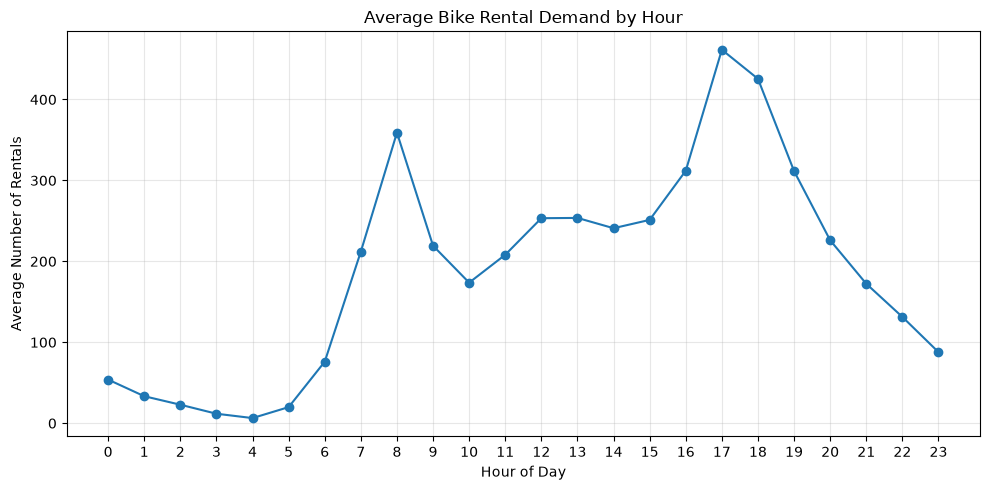

In [4]:
# Avg hourly rental demand
hourly_demand = df.groupby("hr")["cnt"].mean()

plt.figure(figsize=(10, 5))

plt.plot(
    hourly_demand.index,
    hourly_demand.values,
    marker="o"
)

plt.title("Average Bike Rental Demand by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Number of Rentals")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


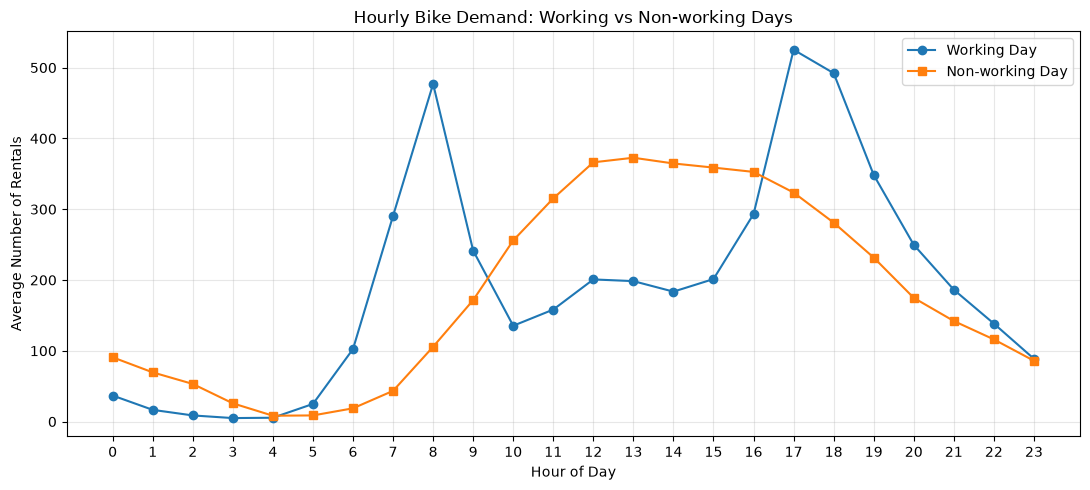

In [5]:
# Compare hourly demand between working & non-working days
hourly_comparison = (
    df.groupby(["workingday", "hr"])["cnt"]
      .mean()
      .unstack(level=0)
)

plt.figure(figsize=(11, 5))

plt.plot(
    hourly_comparison.index,
    hourly_comparison[1],
    marker="o",
    label="Working Day"
)

plt.plot(
    hourly_comparison.index,
    hourly_comparison[0],
    marker="s",
    label="Non-working Day"
)

plt.title("Hourly Bike Demand: Working vs Non-working Days")
plt.xlabel("Hour of Day")
plt.ylabel("Average Number of Rentals")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("../figures/hourly_workingday_comparison.png", dpi=200)
plt.show()


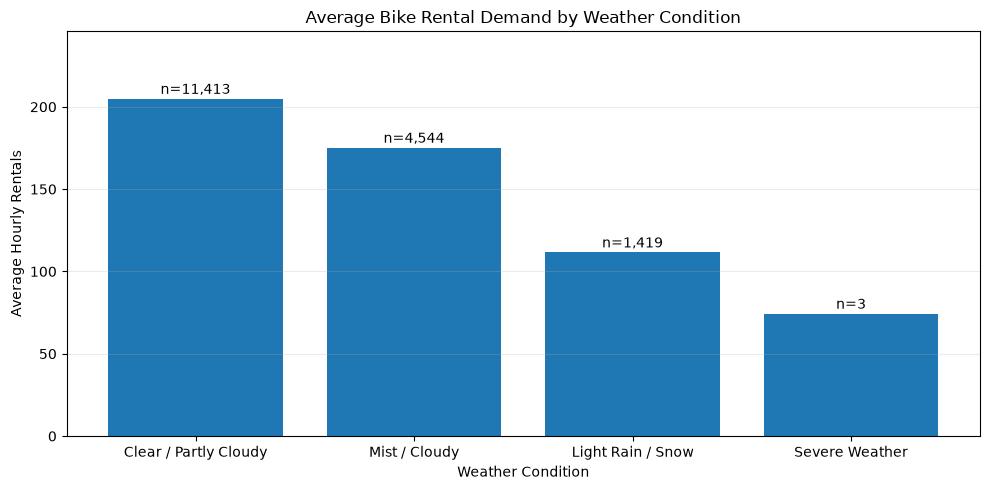

In [7]:

weather_stats = (
    df.groupby("weathersit")["cnt"]
    .agg(["count", "mean"])
)

weather_labels = {
    1: "Clear / Partly Cloudy",
    2: "Mist / Cloudy",
    3: "Light Rain / Snow",
    4: "Severe Weather"
}

labels = [weather_labels[i] for i in weather_stats.index]

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(labels, weather_stats["mean"])

for bar, count in zip(bars, weather_stats["count"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 3,
        f"n={count:,}",
        ha="center",
        fontsize=10
    )

ax.set_title("Average Bike Rental Demand by Weather Condition")
ax.set_xlabel("Weather Condition")
ax.set_ylabel("Average Hourly Rentals")
ax.set_ylim(0, weather_stats["mean"].max() * 1.2)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig("../figures/weather_demand.png", dpi=200)
plt.show()



# Feature engineering 

## Data splitting

In [8]:
# Convert
df["dteday"] = pd.to_datetime(df["dteday"])

# Sort 
df = df.sort_values(
    ["dteday", "hr"]
).reset_index(drop=True)

features = [
    "season",
    "yr",
    "mnth",
    "hr",
    "holiday",
    "weekday",
    "workingday",
    "weathersit",
    "temp",
    "atemp",
    "hum",
    "windspeed"
]

X = df[features].copy()
y = df["cnt"].copy()

print("Feature matrix:", X.shape)
print("Target vector:", y.shape)
display(X.head())

Feature matrix: (17379, 12)
Target vector: (17379,)


,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed
0,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0
1,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0
2,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0
3,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0
4,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0


In [ ]:

# Use the date at the 80% boundary as the cutoff
split_idx = int(len(df) * 0.8)
cutoff_date = df.loc[split_idx, "dteday"]

# Keep complete days in separate sets
train_mask = df["dteday"] < cutoff_date
test_mask = df["dteday"] >= cutoff_date

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

print("Training ends:",
      df.loc[train_mask, "dteday"].max().date())

print("Test starts:",
      df.loc[test_mask, "dteday"].min().date())


Training samples: 13891
Test samples: 3488
Training ends: 2012-08-06
Test starts: 2012-08-07


# Model training & evaluation

## Historical Average Baseline 

### 未来某个小时的demand可只用历史上相同小时/工作日状态的平均rnt来估计！

In [11]:
val_split = int(len(X_train) * 0.8)

X_fit = X_train.iloc[:val_split]
X_val = X_train.iloc[val_split:]

y_fit = y_train.iloc[:val_split]
y_val = y_train.iloc[val_split:]

# Calculate historical averages by hour and working-day 
baseline_data = X_fit[["hr", "workingday"]].copy()
baseline_data["cnt"] = y_fit

hourly_means = (
    baseline_data
    .groupby(["hr", "workingday"])["cnt"]
    .mean()
)

global_mean = y_fit.mean()

# Predict validation demand using historical averages
baseline_pred = [
    hourly_means.get(
        (hr, workingday),
        global_mean
    )
    for hr, workingday in zip(
        X_val["hr"],
        X_val["workingday"]
    )
]

print("Baseline predictions:", len(baseline_pred))
print("First 5 predictions:", baseline_pred[:5])


Baseline predictions: 2779
First 5 predictions: [np.float64(19.059748427672957), np.float64(80.94670846394985), np.float64(227.39811912225704), np.float64(385.1880877742947), np.float64(198.53291536050156)]


In [13]:
# Error of Model 1

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

baseline_mae = mean_absolute_error(y_val, baseline_pred)
baseline_rmse = np.sqrt(
    mean_squared_error(y_val, baseline_pred)
)
baseline_r2 = r2_score(y_val, baseline_pred)

print(f"Baseline MAE:  {baseline_mae:.2f}")
print(f"Baseline RMSE: {baseline_rmse:.2f}")
print(f"Baseline R²:   {baseline_r2:.3f}")


Baseline MAE:  124.63
Baseline RMSE: 166.63
Baseline R²:   0.409


## Linear regression


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Categorical
categorical_features = [
    "season", "mnth", "hr",
    "holiday", "weekday",
    "workingday", "weathersit"
]

# Numerical 
numerical_features = [
    "yr", "temp", "atemp",
    "hum", "windspeed"
]

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("num", StandardScaler(), numerical_features)
    ]
)

# Linear regression pipeline
lr_model = Pipeline([
    ("preprocessing", preprocessor),
    ("regressor", LinearRegression())
])

# Train model
lr_model.fit(X_fit, y_fit)

# Predict validation data
lr_pred = lr_model.predict(X_val)

# Evaluate
lr_mae = mean_absolute_error(y_val, lr_pred)
lr_rmse = np.sqrt(mean_squared_error(y_val, lr_pred))
lr_r2 = r2_score(y_val, lr_pred)

print(f"Linear Regression MAE:  {lr_mae:.2f}")
print(f"Linear Regression RMSE: {lr_rmse:.2f}")
print(f"Linear Regression R²:   {lr_r2:.3f}")

Linear Regression MAE:  108.39
Linear Regression RMSE: 136.31
Linear Regression R²:   0.604


## Random forest

In [23]:
from sklearn.ensemble import RandomForestRegressor
from time import perf_counter

rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=18,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

start = perf_counter()

rf_model.fit(X_fit, y_fit)

training_time = perf_counter() - start

rf_pred = rf_model.predict(X_val)

rf_mae = mean_absolute_error(y_val, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_val, rf_pred))
rf_r2 = r2_score(y_val, rf_pred)

print(f"Random Forest MAE:  {rf_mae:.2f}")
print(f"Random Forest RMSE: {rf_rmse:.2f}")
print(f"Random Forest R²:   {rf_r2:.3f}")
print(f"Training time:      {training_time:.2f} seconds")

Random Forest MAE:  49.80
Random Forest RMSE: 74.21
Random Forest R²:   0.883
Training time:      0.43 seconds


# Model Evaluation & Visualization

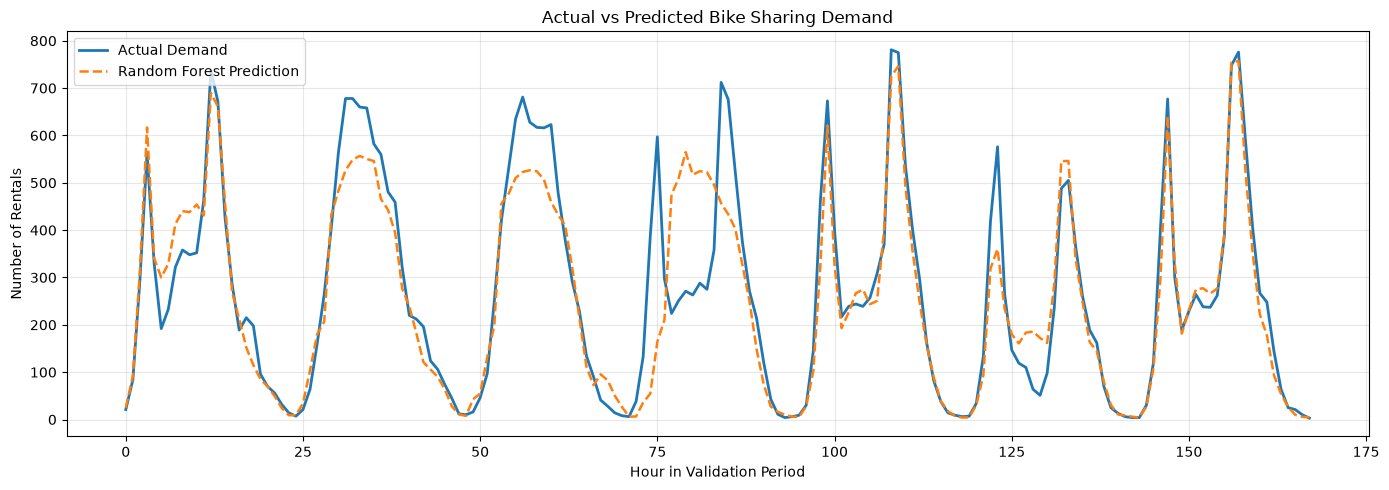

In [24]:
import matplotlib.pyplot as plt
import numpy as np

n = 168

actual = y_val.iloc[:n].to_numpy()
predicted = rf_pred[:n]

plt.figure(figsize=(14, 5))

plt.plot(
    actual,
    label="Actual Demand",
    linewidth=2
)

plt.plot(
    predicted,
    label="Random Forest Prediction",
    linewidth=1.8,
    linestyle="--"
)

plt.title("Actual vs Predicted Bike Sharing Demand")
plt.xlabel("Hour in Validation Period")
plt.ylabel("Number of Rentals")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../figures/actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


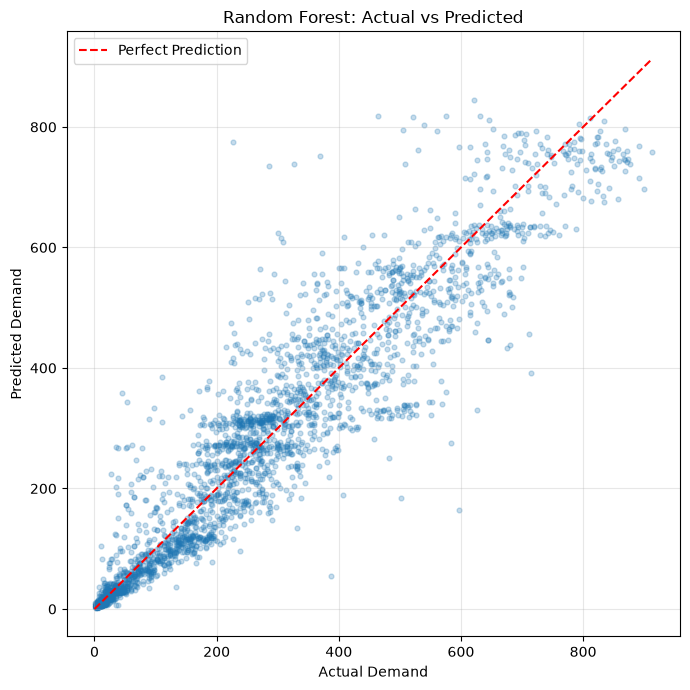

In [25]:
plt.figure(figsize=(7, 7))

plt.scatter(
    y_val,
    rf_pred,
    alpha=0.25,
    s=12
)

max_value = max(y_val.max(), rf_pred.max())

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--",
    color="red",
    label="Perfect Prediction"
)

plt.xlabel("Actual Demand")
plt.ylabel("Predicted Demand")
plt.title("Random Forest: Actual vs Predicted")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../figures/prediction_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


hr            0.6253
atemp         0.0849
temp          0.0721
workingday    0.0579
yr            0.0395
hum           0.0349
weathersit    0.0205
season        0.0197
mnth          0.0197
weekday       0.0126
windspeed     0.0117
holiday       0.0013
dtype: float64


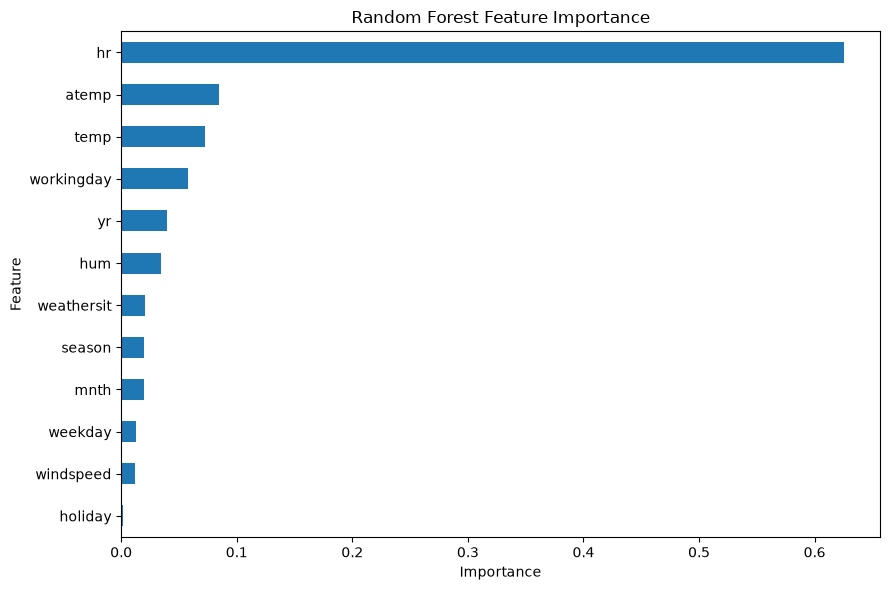

In [26]:

import pandas as pd

importance = pd.Series(
    rf_model.feature_importances_,
    index=X_fit.columns
).sort_values(ascending=False)

print(importance.round(4))

plt.figure(figsize=(9, 6))

importance.sort_values().plot.barh()

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()

plt.savefig(
    "../figures/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Evaluation of model on test set

In [27]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# Final model with the selected configuration
final_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=18,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Retrain using all training data
final_model.fit(X_train, y_train)

# Evaluate on the untouched test set
test_pred = final_model.predict(X_test)

test_mae = mean_absolute_error(y_test, test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))
test_r2 = r2_score(y_test, test_pred)

print(f"Final Test MAE:  {test_mae:.2f}")
print(f"Final Test RMSE: {test_rmse:.2f}")
print(f"Final Test R²:   {test_r2:.3f}")


Final Test MAE:  44.94
Final Test RMSE: 69.81
Final Test R²:   0.900


In [28]:
final_results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Validation": [rf_mae, rf_rmse, rf_r2],
    "Test": [test_mae, test_rmse, test_r2]
})

display(final_results.round(3))

final_results.to_csv(
    "../data/model_results.csv",
    index=False
)


,Metric,Validation,Test
0,MAE,49.799,44.944
1,RMSE,74.214,69.808
2,R2,0.883,0.900
